In [2]:
import Pkg

project_dir = let dir = pwd()
    while !isfile(joinpath(dir, "Project.toml")) && dirname(dir) != dir
        dir = dirname(dir)
    end
    isfile(joinpath(dir, "Project.toml")) || error("No se encontró Project.toml; abre el notebook desde el repositorio.")
    dir
end

Pkg.activate(project_dir)

  Activating project at `c:\Users\Santiago Avalloni\Desktop\COPTI\guiado-proyectiles`


# Problema no lineal

Del [modelamiento no lineal](../../docs/modelo_no_lineal.md), tenemos el siguiente problema de Bolza.

$$
\min_{\substack{T>0\\u\in L^\infty([0,T],U)}}
J(u,T):=\int_0^T \frac{\alpha}{2} u^2(t) + \beta \,dt,
$$

sujeto a la dinámica no lineal, la condición inicial $x(0)=x_0$ y la condición terminal

$$
h(x(T))=0,\qquad h(x):=r_x^2+r_y^2-\varepsilon^2,
$$

de modo que la dinámica enstá en una región donde $R>0$ y no aparece la singularidad en $R=0$. 

Para las simulaciones, asumimos sin pérdida de generalidad que la LOS inicial es paralela al eje $x$, pues en caso contrario basta rotar el sistema.

## Simulaciones

In [3]:
using OptimalControl
using NLPModelsIpopt
using Plots


ESTILO_PLOTS = (
    titlefontsize = 24,
    guidefontsize = 24,
    tickfontsize = 18,
    legendfontsize = 18,
    legend = false # :outerright,
)

Plots.default(
    ; ESTILO_PLOTS...,
    linewidth = 3,
	gridlinewidth = 1,
    grid = true,
    gridalpha = 0.8,
    left_margin = 14Plots.mm,
    bottom_margin = 10Plots.mm,
    top_margin = 5Plots.mm,
    right_margin = 5Plots.mm,
    size = (1400, 900),
	ylims= (-60, 0),
	dpi=400
)

RUTA_PLOTS = "no_lineal/"
RUTA_RESULTADOS = joinpath(project_dir, "outputs", RUTA_PLOTS)
mkpath(RUTA_RESULTADOS)


function guardar_plot(grafico, nombre_archivo)
    Plots.savefig(grafico, joinpath(RUTA_RESULTADOS, nombre_archivo))
    return grafico
end


function persecucion_no_lineal(
    t0,
    x0;
    rapidez_M::Real = 5, 
    alpha::Real = 1.0,
    beta::Real = 1.5,
    epsilon::Real = 5e-2,
    max_T::Real = 20,
    max_u::Real = 5,
)
    radio_inicial = hypot(x0[1], x0[2])

    ocp = @def begin
        tf ∈ R, variable
        t ∈ [t0, tf], time
        x = (rx, ry, theta) ∈ R^3, state
        u ∈ R, control

        t0 <= tf <= max_T
        -max_u ≤ u(t) ≤ max_u
        rx(t)^2 + ry(t)^2 >= epsilon^2

        x(t0) == x0
        rx(tf)^2 + ry(tf)^2 == epsilon^2

        ẋ(t) == [
            -rapidez_M * cos(theta(t)),
            -rapidez_M * sin(theta(t)),
            u(t) / rapidez_M * (
                rx(t) * cos(theta(t)) +
                ry(t) * sin(theta(t))
            ) / (sqrt(rx(t)^2 + ry(t)^2) + 1e-4)  # Sumamos un pequeño delta para evitar problemas numéricos
        ]

        ∫(0.5*alpha*u(t)^2 + beta) → min
    end

    return ocp
end


persecucion_no_lineal (generic function with 1 method)

In [4]:
# Datos del problema
pos_target = [60.0, 0.0]
pos_proyectil = [0.0, 0.0]

vel_proyectil = [5.0, 0.0]
rapidez_proyectil = hypot(vel_proyectil[1], vel_proyectil[2])

r0 = pos_target - pos_proyectil
theta0 = atan(vel_proyectil[2], vel_proyectil[1])

t0 = 0.0
x0 = [r0[1], r0[2], theta0]

println("Tiempo inicial: $(t0)")
println("Condición inicial: $(x0)")

desvios_angulares_deg = [-95.0, -90.0, -85.0, -50.0, 0.0]

angulos_iniciales = theta0 .+ deg2rad.(desvios_angulares_deg)


Tiempo inicial: 0.0
Condición inicial: [60.0, 0.0, 0.0]


5-element Vector{Float64}:
 -1.6580627893946132
 -1.5707963267948966
 -1.4835298641951802
 -0.8726646259971648
  0.0

In [ ]:
function solucion_alpha_beta(;
    alpha::Real = 1.0,
    beta::Real = 1.5,
    tiempo_inicial::Real = t0,
    posicion_objetivo::AbstractVector{<:Real} = pos_target,
    posicion_inicial::AbstractVector{<:Real} = pos_proyectil,
    rapidez::Real = rapidez_proyectil,
    angulos::AbstractVector{<:Real} = angulos_iniciales,
    epsilon::Real = 5e-2,
    max_T::Real = 20,
    max_u::Real = 5,
    grid_size::Integer = 50,
    max_iter::Integer = 700,
    lim_x::Tuple,
    lim_y::Tuple,
)
    posicion_relativa = posicion_objetivo - posicion_inicial
    soluciones = map(angulos) do theta_inicial
        estado_inicial = [posicion_relativa[1], posicion_relativa[2], theta_inicial]
        problema = persecucion_no_lineal(
            tiempo_inicial, estado_inicial;
            rapidez_M = rapidez, alpha = alpha, beta = beta,
            epsilon = epsilon, max_T = max_T, max_u = max_u,
        )

        println("Resolviendo para θ₀ = $(round(rad2deg(theta_inicial), digits=1))°, α = $alpha, β = $beta")
        @time solve(problema; grid_size = grid_size, max_iter = max_iter)
    end

    grafico = plot(
        xlabel = "Eje X",
        ylabel = "Eje Y",
        title = "Trayectorias del misil (α = $alpha, β = $beta)",
        # aspect_ratio = :equal,
        legend = ESTILO_PLOTS.legend,
    )

	colores = (
        "#0072B2",
        "#D55E00",
        "#009E73",
        "#CC79A7",
        "#A6761D",
        "#332288",
        "#882255",
        "#117733",
    )
    for (theta_inicial, solucion, color) in zip(angulos, soluciones, colores)
        tiempos = time_grid(solucion)
        estado_relativo = state(solucion)
        trayectoria_x = [posicion_objetivo[1] - estado_relativo(t)[1] for t in tiempos]
        trayectoria_y = [posicion_objetivo[2] - estado_relativo(t)[2] for t in tiempos]
        etiqueta = "θ₀ = $(round(rad2deg(theta_inicial), digits=1))°"
        plot!(grafico, trayectoria_y, trayectoria_x; label = etiqueta, linewidth = 3, color=color)
    end

    scatter!(grafico, [posicion_inicial[2]], [posicion_inicial[1]];
        label = " Inicio del misil", marker = :circle, markersize = 9)
    scatter!(grafico, [posicion_objetivo[2]], [posicion_objetivo[1]];
        label = " Objetivo", marker = :circle, markersize = 9)
    Plots.xlims!(grafico, lim_x)
    Plots.ylims!(grafico, lim_y)
    return guardar_plot(grafico, "trayectorias_alpha_$(alpha)_beta_$(beta).png")
end


solucion_alpha_beta (generic function with 1 method)

Resolviendo para θ₀ = -95.0°, α = 1.0, β = 1.5
▫ This is OptimalControl 2.0.4, solving with: collocation → adnlp → ipopt (cpu)

  📦 Configuration:
   ├─ Discretizer: collocation (grid_size = 50)
   ├─ Modeler: adnlp
   └─ Solver: ipopt (max_iter = 700)

▫ This is Ipopt version 3.14.19, running with linear solver MUMPS 5.9.0.

Number of nonzeros in equality constraint Jacobian...:      905
Number of nonzeros in inequality constraint Jacobian.:      102
Number of nonzeros in Lagrangian Hessian.............:     1309

Total number of variables............................:      204
                     variables with only lower bounds:        0
                variables with lower and upper bounds:       51
                     variables with only upper bounds:        0
Total number of equality constraints.................:      154
Total number of inequality constraints...............:       51
        inequality constraints with only lower bounds:       51
   inequality constraints with 

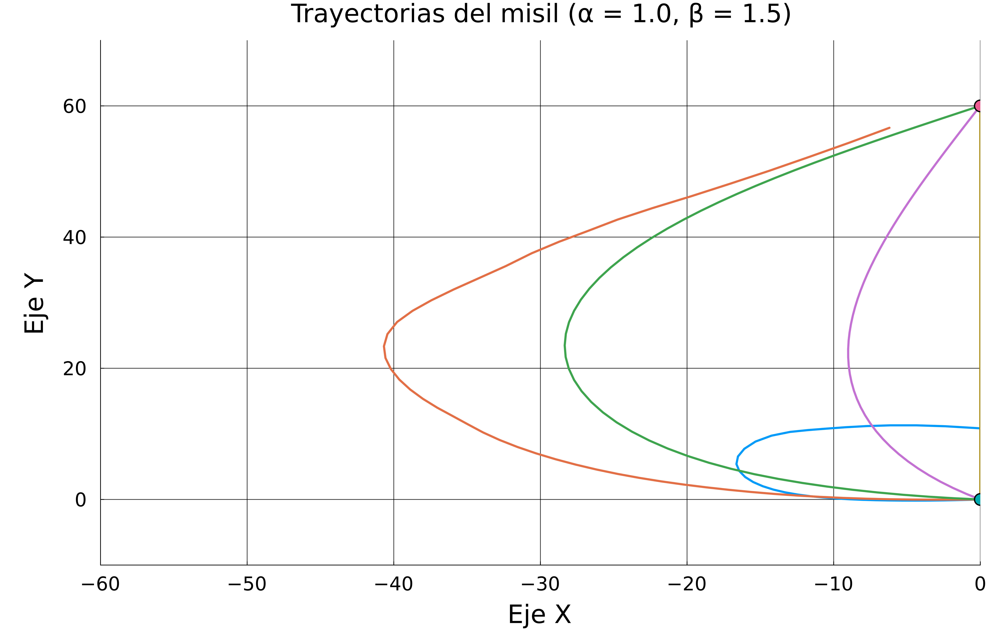

In [6]:
plt1 = solucion_alpha_beta(;
    alpha = 1.0, beta = 1.5, lim_x = (-60, 0), lim_y = (-10, 70)
)

Resolviendo para θ₀ = -95.0°, α = 0.001, β = 1.5
▫ This is OptimalControl 2.0.4, solving with: collocation → adnlp → ipopt (cpu)

  📦 Configuration:
   ├─ Discretizer: collocation (grid_size = 50)
   ├─ Modeler: adnlp
   └─ Solver: ipopt (max_iter = 700)

▫ This is Ipopt version 3.14.19, running with linear solver MUMPS 5.9.0.

Number of nonzeros in equality constraint Jacobian...:      905
Number of nonzeros in inequality constraint Jacobian.:      102
Number of nonzeros in Lagrangian Hessian.............:     1309

Total number of variables............................:      204
                     variables with only lower bounds:        0
                variables with lower and upper bounds:       51
                     variables with only upper bounds:        0
Total number of equality constraints.................:      154
Total number of inequality constraints...............:       51
        inequality constraints with only lower bounds:       51
   inequality constraints wit

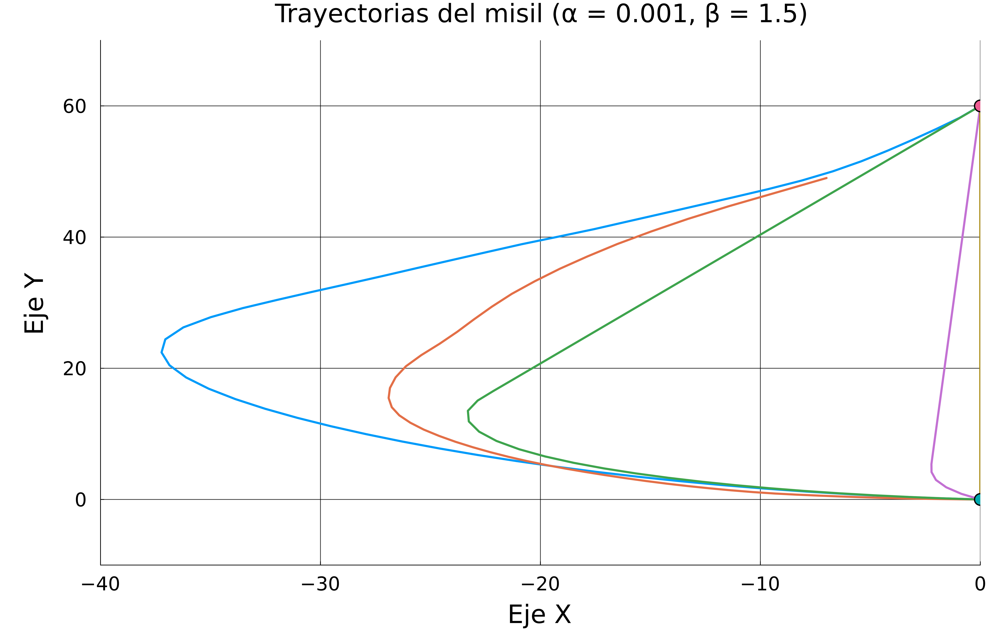

In [7]:
plt2 = solucion_alpha_beta(;
    alpha = 0.001, beta = 1.5,lim_x = (-40, 0), lim_y = (-10, 70)
)

Resolviendo para θ₀ = -95.0°, α = 1.0, β = 0.001
▫ This is OptimalControl 2.0.4, solving with: collocation → adnlp → ipopt (cpu)

  📦 Configuration:
   ├─ Discretizer: collocation (grid_size = 50)
   ├─ Modeler: adnlp
   └─ Solver: ipopt (max_iter = 700)

▫ This is Ipopt version 3.14.19, running with linear solver MUMPS 5.9.0.

Number of nonzeros in equality constraint Jacobian...:      905
Number of nonzeros in inequality constraint Jacobian.:      102
Number of nonzeros in Lagrangian Hessian.............:     1309

Total number of variables............................:      204
                     variables with only lower bounds:        0
                variables with lower and upper bounds:       51
                     variables with only upper bounds:        0
Total number of equality constraints.................:      154
Total number of inequality constraints...............:       51
        inequality constraints with only lower bounds:       51
   inequality constraints wit

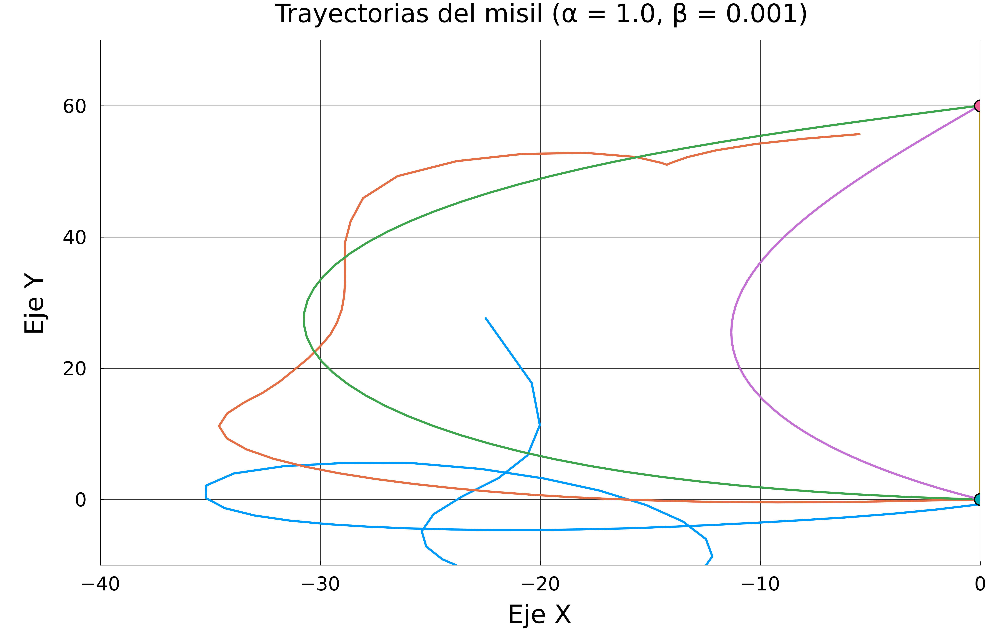

In [8]:
plt3 = solucion_alpha_beta(;
    alpha = 1.0, beta = 0.001, lim_x = (-40, 0), lim_y = (-10, 70)
)

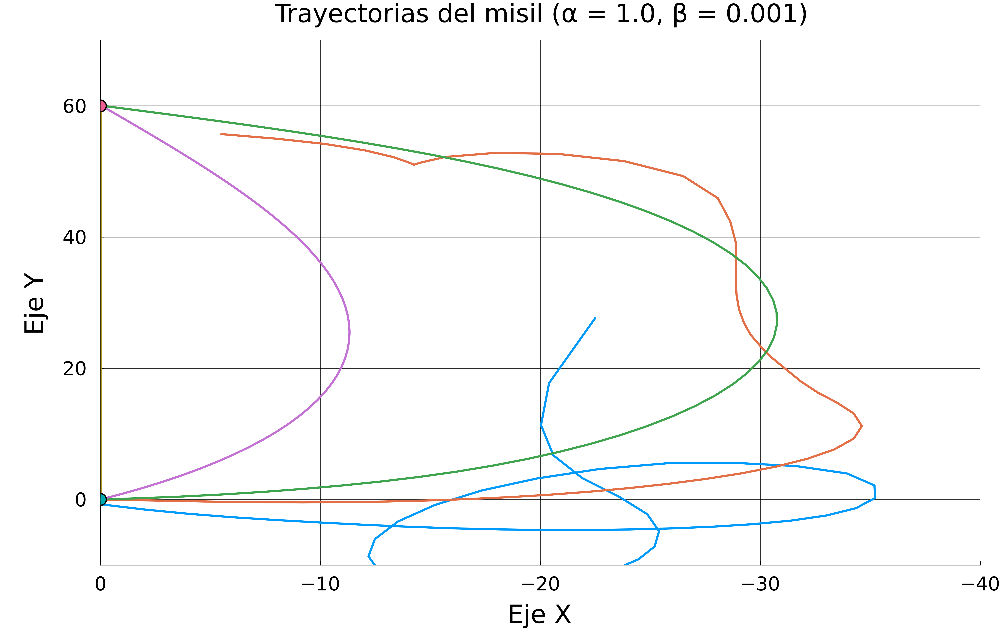

In [9]:
Plots.plot!(plt3, xflip=true)

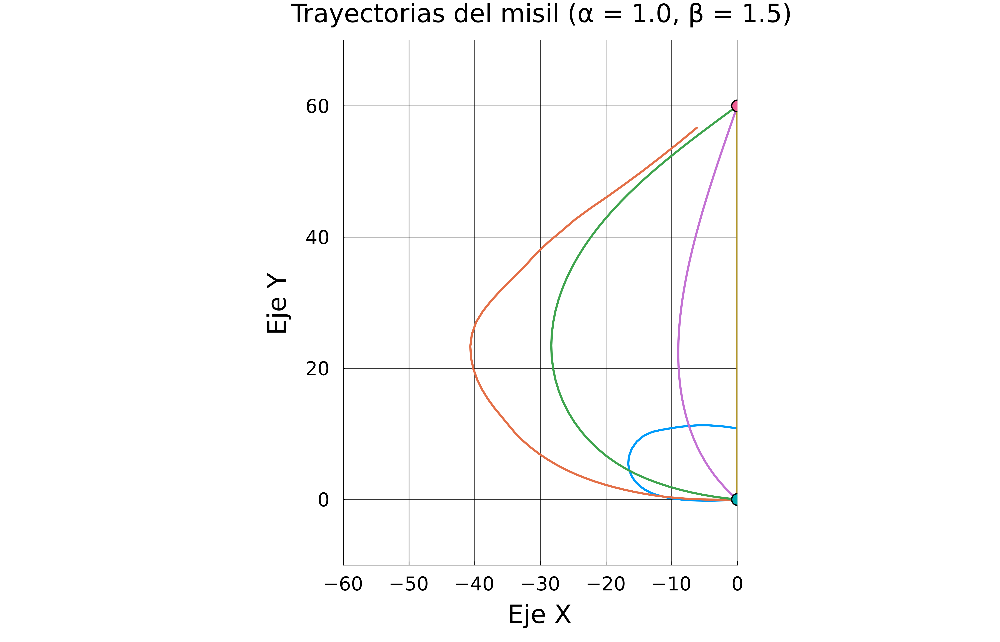

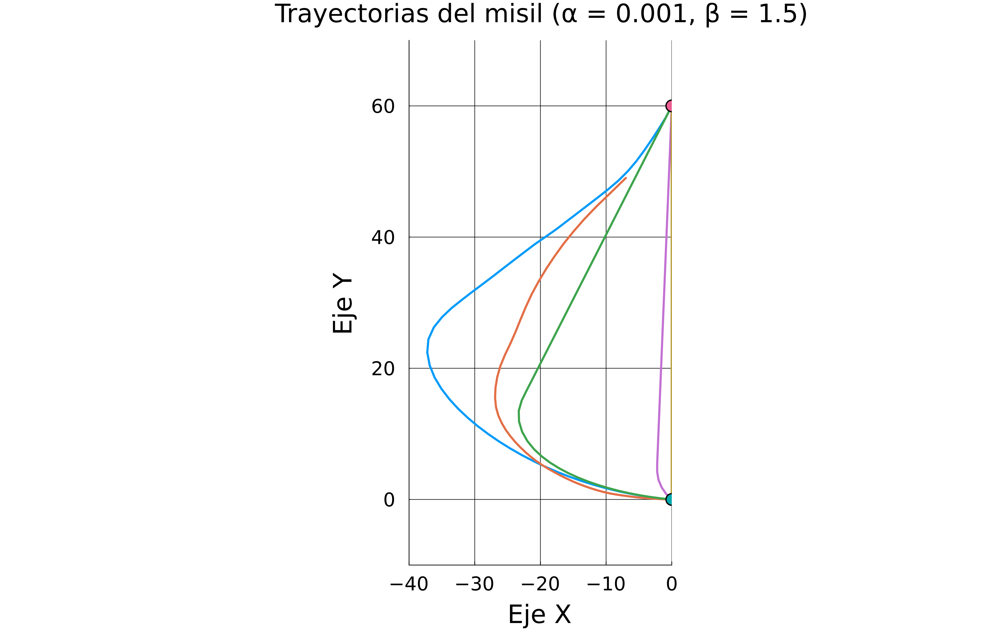

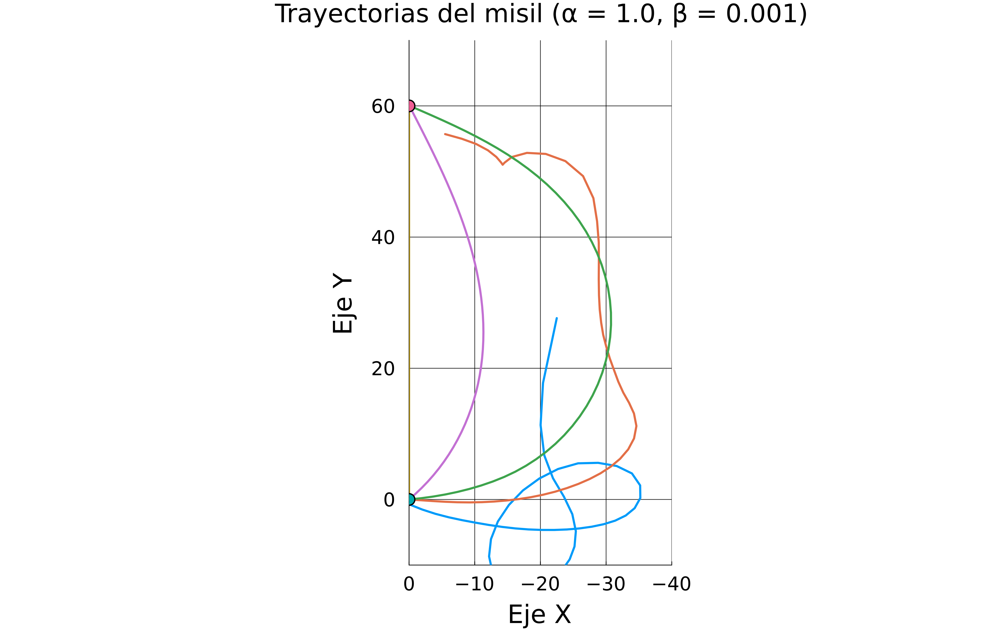

In [10]:

Plots.plot!(plt1, aspect_ratio=:equal)
Plots.plot!(plt2, aspect_ratio=:equal)
Plots.plot!(plt3, aspect_ratio=:equal)


# Plots.plot!(plt1, legend=:outer)

display(plt1)
display(plt2)
display(plt3)


In [11]:
Plots.plot!(plt3, ylabel="")
Plots.plot!(plt3, legend=:outerright)
Plots.plot!(plt3, ymirror=false)
plt3[:size]

(1400, 900)

In [12]:
plt2[:size]

(1400, 900)

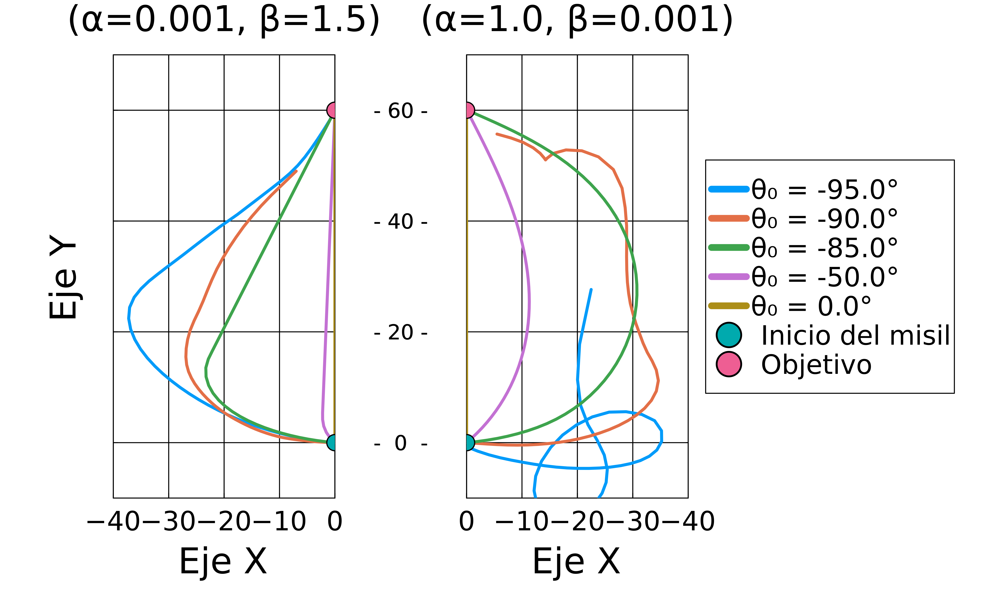

In [34]:
# 2. Create an invisible dummy plot solely to hold the legend
# Note: Pass a 1xN row matrix (e.g., [0 0 0]) so each series gets an entry
# leg = Plots.plot([0 0 0 0 0 0 0 0 0], 
#     showaxis = false, 
#     grid = false, 
#     lims = (1, 2), # Hides the dummy points outside the view
#     labels = ["  θ₀ = -95.0°" "  θ₀ = -95.0°" "  θ₀ = -95.0°" "  θ₀ = -95.0°" "  θ₀ = -95.0°" "  θ₀ = -95.0°" "  θ₀ = -95.0°" "  θ₀ = -95.0°" "  θ₀ = -95.0°"], 
#     legend = :left,
# 	foreground_color_legend = nothing,   # Removes the box outline (alias: fg_legend = :transparent)
#     background_color_legend = nothing,
# 	framestyle = :none
# )

Plots.plot!(plt1, title="(α=1.0, β=1.5)")
Plots.plot!(plt2, title="(α=0.001, β=1.5)")
Plots.plot!(plt3, title="(α=1.0, β=0.001)")
Plots.plot!(plt2, ylabel="Eje Y")
Plots.plot!(plt2, yaxis=true, yformatter = _ -> "")
Plots.plot!(plt3, yaxis=true, yformatter = _ -> "")

# Plots.plot!(plt3, legend=(1.2, 0.8), right_margin=65Plots.mm)

Plots.plot!(plt2, foreground_color_border = :black, framestyle = :box)
Plots.plot!(plt3, foreground_color_border = :black, framestyle = :box)

# 3. Combine using @layout, giving the legend subplot a small width (e.g., 15%)
layout = @layout [a b{0.686w}]
plt4 = Plots.plot(plt2, plt3;
	layout		= layout,
	# link		= :y,
	size		= (1000, 600),
	dpi			= 600,
	ylims       = (-10, 70),
    xlims       = (-40, 0),
	annotations	= [(11.9, 0, "-  0  -"), (11.9, 20, "- 20 -"), (11.9, 40, "- 40 -"), (11.9, 60, "- 60 -")]
)
guardar_plot(plt4,"comparacion.png")
